<a href="https://colab.research.google.com/github/afif-af/Natural-Language-Processing/blob/main/Long_Short_Term_Memory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

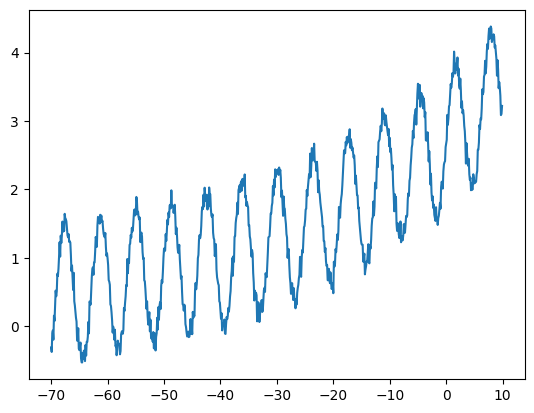

In [ ]:
X_t=np.arange(-70, 10, 0.1)
X_t=X_t.reshape(len(X_t),1)

Y_t=np.sin(X_t) + 0.1 *np.random.randn(len(X_t),1) + np.exp((0.5 *X_t +20) *0.05)
plt.plot(X_t, Y_t)
plt.show()


In [ ]:
class Sigmoid:
  def forward(self, M):
    sigm        =np.clip(1/(1 +np.exp(-M)), 1e-7 , 1e-7)
    self.output =sigm
    self.inputs =sigm

  def backward(self, dvalues):
    sigm         =self.inputs
    deriv        =np.multiply(sigm, (1-sigm))
    self.dinputs =np.multiply(deriv, dvalues)


In [ ]:
class Tanh:
  def forward(self, inputs):
    self.output =np.tanh(inputs)
    self.inputs =inputs

  def backward(self, dvalues):
    deriv        =1 - self.output **2
    self.dinputs =np.multiply(deriv, dvalues)

In [ ]:
class LSTM():
  def __init__(self, n_neurons):

    self.n_neurons =n_neurons

    self.Uf   =0.1 * np.random.rand(n_neurons, 1)
    self.bf   =0.1 * np.random.rand(n_neurons, 1)
    self.wf   =0.1 * np.random.rand(n_neurons, n_neurons)

    self.Ui   =0.1 * np.random.rand(n_neurons, 1)
    self.bi   =0.1 * np.random.rand(n_neurons, 1)
    self.Wi   =0.1 * np.random.rand(n_neurons, n_neurons)

    self.Uo   =0.1 * np.random.rand(n_neurons, 1)
    self.bo   =0.1 * np.random.rand(n_neurons, 1)
    self.Wo   =0.1 * np.random.rand(n_neurons, n_neurons)

    self.Ug   =0.1 * np.random.rand(n_neurons, 1)
    self.bg   =0.1 * np.random.rand(n_neurons, 1)
    self.Wg   =0.1 * np.random.rand(n_neurons, n_neurons)


  def forward(self, X_t):
    T =max(X_t.shape)

    self.T =T
    self.X_T =X_t

    n_neurons =self.n_neurons

    self.H       =[np.zeros((n_neurons, 1)) for t in range(T+1)]
    self.C       =[np.zeros((n_neurons, 1)) for t in range(T+1)]
    self.C_tidle =[np.zeros((n_neurons, 1)) for t in range(T)]


    self.F       =[np.zeros((n_neurons, 1)) for t in range(T+1)]
    self.O       =[np.zeros((n_neurons, 1)) for t in range(T+1)]
    self.I       =[np.zeros((n_neurons, 1)) for t in range(T)]


    # forget
    self.dUf     =0.1 * np.random.rand(n_neurons, 1)
    self.dbf     =0.1 * np.random.rand(n_neurons, 1)
    self.dWf     =0.1 * np.random.rand(n_neurons, n_neurons)
    #  input
    self.dUi     =0.1 * np.random.rand(n_neurons, 1)
    self.dbi     =0.1 * np.random.rand(n_neurons, 1)
    self.dWi     =0.1 * np.random.rand(n_neurons, n_neurons)
    #  output
    self.dUo     =0.1 * np.random.rand(n_neurons, 1)
    self.dbo     =0.1 * np.random.rand(n_neurons, 1)
    self.dWo     =0.1 * np.random.rand(n_neurons, n_neurons)
    # c tidle
    self.dUg     =0.1 * np.random.rand(n_neurons, 1)
    self.dbg     =0.1 * np.random.rand(n_neurons, 1)
    self.dWg     =0.1 * np.random.rand(n_neurons, n_neurons)

    Sigmf        =[Sigmoid() for i in range(T)]
    Sigmi        =[Sigmoid() for i in range(T)]
    Sigmo        =[Sigmoid() for i in range(T)]

    Tanh1        =[Tanh() for t in range(T)]
    Tanh2        =[Tanh() for t in range(T)]

    ht   =self.H[0]
    ct   =self.C[0]

    #call LSTMCell
    [H, C, Sigmf, Sigmi, Sigmo, Tanh1, Tanh2, F, O, I, C_tidle] =self.LSTMCell(X_t, ht, ct, Sigmf, Sigmi, Sigmo, Tanh1, Tanh2, \
                                                                               self.H, self.C, self.F, self.O, self.I, self.C_tidle )

    self.F       =F
    self.O       =O
    self.I       =I
    self.C_tidle =C_tidle

    self.H  =H
    self.C  =C

    self.Sigmf  =Sigmf
    self.Sigmi  =Sigmi
    self.Sigmo  =Sigmo

    self.Tanh1  =Tanh1
    self.Tanh2  =Tanh2


  def LSTMCell(self, X_t, ht, ct, Sigmf, Sigmi, Sigmo, Tanh1, Tanh2, H,C, F,O,I,C_tidle):

    for t , xt in enumerate(X_t):
      xt=xt.reshape(1,1)

      outf =np.dot(self.Uf, xt) +np.dot(self.wf, ht) +self.bf
      Sigmf[t].forward(outf)
      ft =Sigmf[t].output

      outi =np.dot(self.Ui, xt) + np.dot(self.Wi, ht) +self.bi
      Sigmi[t].forward(outi)
      it   =Sigmi[t].output

      outo =np.dot(self.Uo, xt)  + np.dot(self.Wo, ht) +self.bo
      Sigmo[t].forward(outo)
      ot   =Sigmo[t].output

      outct_tidle =np.dot(self.Ug, xt) +np.dot(self.Wg, ht ) +self.bg
      Tanh1[t].forward(outct_tidle)
      ct_tidle   =Tanh1[t].output



      ct=np.multiply(ft, ct) +np.multiply (it, ct_tidle)

      Tanh2[t].forward(ct)
      ht        =np.multiply(Tanh2[t].output,ot)

      H[t+1] =ht
      C[t+1] =ct
      C_tidle[t] =ct_tidle

      F[t]  =ft
      O[t]  =ot
      I[t]  =it



    return (H, C, Sigmf, Sigmi, Sigmo, Tanh1, Tanh2, F, O, I, C_tidle)


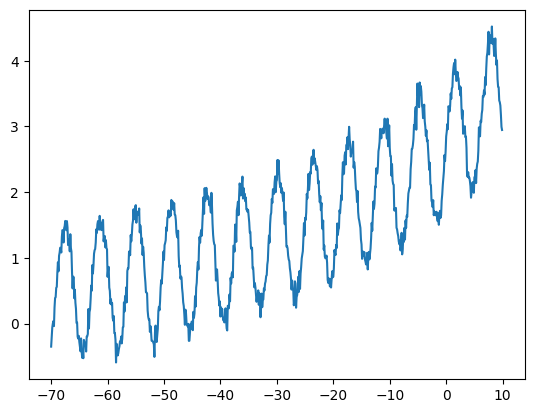

In [ ]:
X_t=np.arange(-70, 10, 0.1)
X_t=X_t.reshape(len(X_t),1)

Y_t=np.sin(X_t) + 0.1 *np.random.randn(len(X_t),1) + np.exp((0.5 *X_t +20) *0.05)
plt.plot(X_t, Y_t)
plt.show()

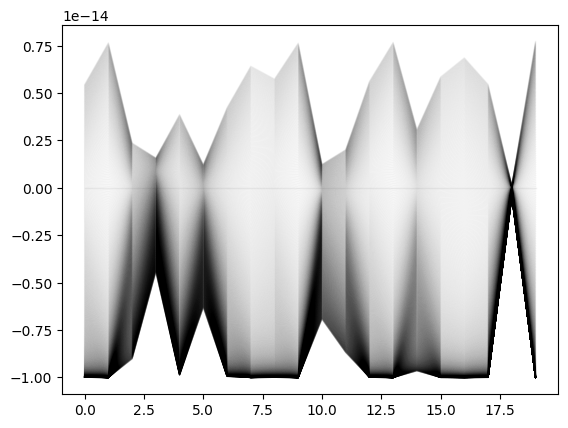

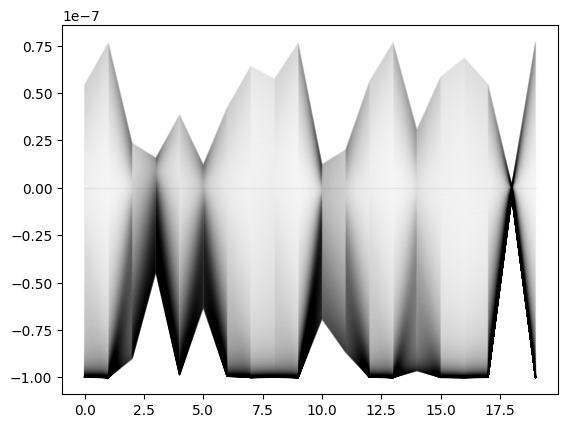

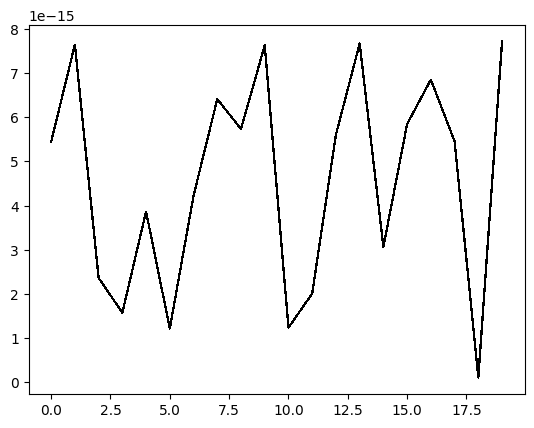

In [ ]:
lstm=LSTM(n_neurons=200)
lstm.forward(X_t)

for h in lstm.H:
  plt.plot(np.arange(20), h[0:20], 'k-', linewidth =1, alpha=0.05)

plt.figure()

for c in lstm.C:
  plt.plot(np.arange(20), c[0:20], 'k-', linewidth=1, alpha=0.05)

plt.figure()

for f in lstm.F:
  plt.plot(np.arange(20), h[0:20], 'k-', linewidth=1, alpha=0.05)






In [ ]:
class LSTM():
  def __init__(self, n_neurons):

    self.n_neurons =n_neurons

    self.Uf   =0.1 * np.random.rand(n_neurons, 1)
    self.bf   =0.1 * np.random.rand(n_neurons, 1)
    self.wf   =0.1 * np.random.rand(n_neurons, n_neurons)

    self.Ui   =0.1 * np.random.rand(n_neurons, 1)
    self.bi   =0.1 * np.random.rand(n_neurons, 1)
    self.Wi   =0.1 * np.random.rand(n_neurons, n_neurons)

    self.Uo   =0.1 * np.random.rand(n_neurons, 1)
    self.bo   =0.1 * np.random.rand(n_neurons, 1)
    self.Wo   =0.1 * np.random.rand(n_neurons, n_neurons)

    self.Ug   =0.1 * np.random.rand(n_neurons, 1)
    self.bg   =0.1 * np.random.rand(n_neurons, 1)
    self.Wg   =0.1 * np.random.rand(n_neurons, n_neurons)


  def forward(self, X_t):
    T =max(X_t.shape)

    self.T =T
    self.X_T =X_t

    n_neurons =self.n_neurons

    self.H       =[np.zeros((n_neurons, 1)) for t in range(T+1)]
    self.C       =[np.zeros((n_neurons, 1)) for t in range(T+1)]
    self.C_tidle =[np.zeros((n_neurons, 1)) for t in range(T)]


    self.F       =[np.zeros((n_neurons, 1)) for t in range(T+1)]
    self.O       =[np.zeros((n_neurons, 1)) for t in range(T+1)]
    self.I       =[np.zeros((n_neurons, 1)) for t in range(T)]


    # forget
    self.dUf     =0.1 * np.random.rand(n_neurons, 1)
    self.dbf     =0.1 * np.random.rand(n_neurons, 1)
    self.dWf     =0.1 * np.random.rand(n_neurons, n_neurons)
    #  input
    self.dUi     =0.1 * np.random.rand(n_neurons, 1)
    self.dbi     =0.1 * np.random.rand(n_neurons, 1)
    self.dWi     =0.1 * np.random.rand(n_neurons, n_neurons)
    #  output
    self.dUo     =0.1 * np.random.rand(n_neurons, 1)
    self.dbo     =0.1 * np.random.rand(n_neurons, 1)
    self.dWo     =0.1 * np.random.rand(n_neurons, n_neurons)
    # c tidle
    self.dUg     =0.1 * np.random.rand(n_neurons, 1)
    self.dbg     =0.1 * np.random.rand(n_neurons, 1)
    self.dWg     =0.1 * np.random.rand(n_neurons, n_neurons)

    Sigmf        =[Sigmoid() for i in range(T)]
    Sigmi        =[Sigmoid() for i in range(T)]
    Sigmo        =[Sigmoid() for i in range(T)]

    Tanh1        =[Tanh() for t in range(T)]
    Tanh2        =[Tanh() for t in range(T)]

    ht   =self.H[0]
    ct   =self.C[0]

    #call LSTMCell
    [H, C, Sigmf, Sigmi, Sigmo, Tanh1, Tanh2, F, O, I, C_tidle] =self.LSTMCell(X_t, ht, ct, Sigmf, Sigmi, Sigmo, Tanh1, Tanh2, \
                                                                               self.H, self.C, self.F, self.O, self.I, self.C_tidle )

    self.F       =F
    self.O       =O
    self.I       =I
    self.C_tidle =C_tidle

    self.H  =H
    self.C  =C

    self.Sigmf  =Sigmf
    self.Sigmi  =Sigmi
    self.Sigmo  =Sigmo

    self.Tanh1  =Tanh1
    self.Tanh2  =Tanh2


  def LSTMCell(self, X_t, ht, ct, Sigmf, Sigmi, Sigmo, Tanh1, Tanh2, H,C, F,O,I,C_tidle):

    for t , xt in enumerate(X_t):
      xt=xt.reshape(1,1)

      outf =np.dot(self.Uf, xt) +np.dot(self.wf, ht) +self.bf
      Sigmf[t].forward(outf)
      ft =Sigmf[t].output

      outi =np.dot(self.Ui, xt) + np.dot(self.Wi, ht) +self.bi
      Sigmi[t].forward(outi)
      it   =Sigmi[t].output

      outo =np.dot(self.Uo, xt)  + np.dot(self.Wo, ht) +self.bo
      Sigmo[t].forward(outo)
      ot   =Sigmo[t].output

      outct_tidle =np.dot(self.Ug, xt) +np.dot(self.Wg, ht ) +self.bg
      Tanh1[t].forward(outct_tidle)
      ct_tidle   =Tanh1[t].output



      ct=np.multiply(ft, ct) +np.multiply (it, ct_tidle)

      Tanh2[t].forward(ct)
      ht        =np.multiply(Tanh2[t].output,ot)

      H[t+1] =ht
      C[t+1] =ct
      C_tidle[t] =ct_tidle

      F[t]  =ft
      O[t]  =ot
      I[t]  =it

    return (H, C, Sigmf, Sigmi, Sigmo, Tanh1, Tanh2, F, O, I, C_tidle)

  def backward(self, dvalues):
        #dht = dinputs from the dense layer

        T       = self.T
        H       = self.H
        C       = self.C

        O       = self.O
        I       = self.I
        C_tilde = self.C_tilde

        X_t     = self.X_t

        Sigmf   = self.Sigmf
        Sigmi   = self.Sigmi
        Sigmo   = self.Sigmo
        Tanh1   = self.Tanh1
        Tanh2   = self.Tanh2

        dht     = dvalues[-1,:].reshape(self.n_neurons,1)

        for t in reversed(range(T)):

            #dy = dinputs[t].reshape(1,1)
            xt = X_t[t].reshape(1,1)

            Tanh2[t].backward(dht)
            dtanh2 = Tanh2[t].dinputs

            dhtdtanh = np.multiply(O[t], dtanh2)

            dctdft       = np.multiply(dhtdtanh,C[t-1])
            dctdit       = np.multiply(dhtdtanh,C_tilde[t])
            dctdct_tilde = np.multiply(dhtdtanh,I[t])

            Tanh1[t].backward(dctdct_tilde)
            dtanh1 = Tanh1[t].dinputs

            Sigmf[t].backward(dctdft)
            dsigmf = Sigmf[t].dinputs

            Sigmi[t].backward(dctdit)
            dsigmi = Sigmi[t].dinputs

            Sigmo[t].backward(np.multiply(dht, Tanh2[t].output))
            dsigmo = Sigmo[t].dinputs

            dsigmfdUf = np.dot(dsigmf,xt)
            dsigmfdWf = np.dot(dsigmf,H[t-1].T)

            self.dUf += dsigmfdUf
            self.dWf += dsigmfdWf
            self.dbf += dsigmf

            dsigmidUi = np.dot(dsigmi,xt)
            dsigmidWi = np.dot(dsigmi,H[t-1].T)

            self.dUi += dsigmidUi
            self.dWi += dsigmidWi
            self.dbi += dsigmi

            dsigmodUo = np.dot(dsigmo,xt)
            dsigmodWo = np.dot(dsigmo,H[t-1].T)

            self.dUo += dsigmodUo
            self.dWo += dsigmodWo
            self.dbo += dsigmo

            dtanh1dUg = np.dot(dtanh1,xt)
            dtanh1dWg = np.dot(dtanh1,H[t-1].T)

            self.dUg += dtanh1dUg
            self.dWg += dtanh1dWg
            self.dbg += dtanh1

            #dht
            dht = np.dot(self.Wf, dsigmf) + np.dot(self.Wi, dsigmi) +\
                  np.dot(self.Wo, dsigmo) + np.dot(self.Wg, dtanh1) +\
                  dvalues[t-1,:].reshape(self.n_neurons,1)

        self.H  = H

In [ ]:
n_neurons =200
lstm=LSTM(n_neurons)
T  =max(X_t.shape)
dense1=Layer_Dense(n_inputs, n_neurons)




lr =1e-5
Monitor =np.zeros((100))
for i in range(100):
  lstm.forward(X_t)
  H=np.array(lstm.H)
  H=H.reshape((H.shape[0], H.shape[1]))

  dense1.forward(Hp)

In [ ]:
class Layer_Dense():

  def __init__(self, n_inputs, n_neurons):
    self.weights =0.1*np.random.randn(n_inputs, n_neurons)
    self.biases  =np.zeros((1, n_neurons))

    L2=1e-2
    self.weights_L2 =L2
    self.biases_L2 =L2

    def forward(self, inputs):
      self.output=np.dot(inputs, self.weights) +self.biases
      self.inputs =inputs

    def backward(self, dvalues):
      self.dweights =np.dot(self.inputs.T, dvalues)
      self.dbiases  =np.sum(dvalues, axis=0, keepdims=True)
      self.dinputs  =np.dot(dvalues, self.weights.T)

      self.dbiases  =self.dbiases +2* self.biases_L2 * self.biases
      self.dweights =self.dweights +2* self.weights_L2 * self.weights





In [ ]:
class Optimizer_SGD_LSTM:
    #initializing with a default learning rate of 0.1
    def __init__(self, learning_rate = 1e-3, decay = 0, momentum = 0):
        self.learning_rate         = learning_rate
        self.current_learning_rate = learning_rate
        self.decay                 = decay
        self.iterations            = 0
        self.momentum              = momentum

    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate * \
                (1/ (1 + self.decay*self.iterations))

    def update_params(self, layer):

        #if we use momentum
        if self.momentum:

            #if layer has attribute momentum
            if not hasattr(layer, 'Uf_momentums'):
                layer.Uf_momentums = np.zeros_like(layer.Uf)
                layer.Ui_momentums = np.zeros_like(layer.Ui)
                layer.Uo_momentums = np.zeros_like(layer.Uo)
                layer.Ug_momentums = np.zeros_like(layer.Ug)

                layer.Wf_momentums = np.zeros_like(layer.Wf)
                layer.Wi_momentums = np.zeros_like(layer.Wi)
                layer.Wo_momentums = np.zeros_like(layer.Wo)
                layer.Wg_momentums = np.zeros_like(layer.Wg)

                layer.bf_momentums = np.zeros_like(layer.bf)
                layer.bi_momentums = np.zeros_like(layer.bi)
                layer.bo_momentums = np.zeros_like(layer.bo)
                layer.bg_momentums = np.zeros_like(layer.bg)


            Uf_updates = self.momentum * layer.Uf_momentums - \
                self.current_learning_rate * layer.dUf
            layer.Uf_momentums = Uf_updates

            Ui_updates = self.momentum * layer.Ui_momentums - \
                self.current_learning_rate * layer.dUi
            layer.Ui_momentums = Ui_updates

            Uo_updates = self.momentum * layer.Uo_momentums - \
                self.current_learning_rate * layer.dUo
            layer.Uo_momentums = Uo_updates

            Ug_updates = self.momentum * layer.Ug_momentums - \
                self.current_learning_rate * layer.dUg
            layer.Ug_momentums = Ug_updates

            Wf_updates = self.momentum * layer.Wf_momentums - \
                self.current_learning_rate * layer.dWf
            layer.Wf_momentums = Wf_updates

            Wi_updates = self.momentum * layer.Wi_momentums - \
                self.current_learning_rate * layer.dWi
            layer.Wi_momentums = Wi_updates

            Wo_updates = self.momentum * layer.Wo_momentums - \
                self.current_learning_rate * layer.dWo
            layer.Wo_momentums = Wo_updates

            Wg_updates = self.momentum * layer.Wg_momentums - \
                self.current_learning_rate * layer.dWg
            layer.Wg_momentums = Wg_updates



            bf_updates = self.momentum * layer.bf_momentums - \
                self.current_learning_rate * layer.dbf
            layer.bf_momentums = bf_updates

            bi_updates = self.momentum * layer.bi_momentums - \
                self.current_learning_rate * layer.dbi
            layer.bi_momentums = bi_updates

            bo_updates = self.momentum * layer.bo_momentums - \
                self.current_learning_rate * layer.dbo
            layer.bo_momentums = bo_updates

            bg_updates = self.momentum * layer.bg_momentums - \
                self.current_learning_rate * layer.dbg
            layer.bg_momentums = bg_updates

        else:

            Uf_updates = -self.current_learning_rate * layer.dUf
            Ui_updates = -self.current_learning_rate * layer.dUi
            Uo_updates = -self.current_learning_rate * layer.dUo
            Ug_updates = -self.current_learning_rate * layer.dUg

            Wf_updates = -self.current_learning_rate * layer.dWf
            Wi_updates = -self.current_learning_rate * layer.dWi
            Wo_updates = -self.current_learning_rate * layer.dWo
            Wg_updates = -self.current_learning_rate * layer.dWg

            bf_updates = -self.current_learning_rate * layer.dbf
            bi_updates = -self.current_learning_rate * layer.dbi
            bo_updates = -self.current_learning_rate * layer.dbo
            bg_updates = -self.current_learning_rate * layer.dbg


        layer.Uf += Uf_updates
        layer.Ui += Ui_updates
        layer.Uo += Uo_updates
        layer.Ug += Ug_updates

        layer.Wf += Wf_updates
        layer.Wi += Wi_updates
        layer.Wo += Wo_updates
        layer.Wg += Wg_updates

        layer.bf += bf_updates
        layer.bi += bi_updates
        layer.bo += bo_updates
        layer.bg += bg_updates

    def post_update_params(self):
        self.iterations += 1


In [ ]:
class Optimizer_SGD:
    #initializing with a default learning rate of 0.1
    def __init__(self, learning_rate = 1, decay = 0, momentum = 0):
        self.learning_rate         = learning_rate
        self.current_learning_rate = learning_rate
        self.decay                 = decay
        self.iterations            = 0
        self.momentum              = momentum

    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate * \
                (1/ (1 + self.decay*self.iterations))

    def update_params(self, layer):

        #if we use momentum
        if self.momentum:

            #if layer has attribute "momentum"
            if not hasattr(layer, 'weight_momentums'):
                layer.weight_momentums = np.zeros_like(layer.weights)
                layer.bias_momentums   = np.zeros_like(layer.biases)

            #now the momentum parts
            weight_updates = self.momentum * layer.weight_momentums - \
                self.current_learning_rate * layer.dweights
            layer.weight_momentums = weight_updates

            bias_updates = self.momentum * layer.bias_momentums - \
                self.current_learning_rate * layer.dbiases
            layer.bias_momentums = bias_updates

        else:

            weight_updates = -self.current_learning_rate * layer.dweights
            bias_updates   = -self.current_learning_rate * layer.dbiases

        layer.weights += weight_updates
        layer.biases  += bias_updates

    def post_update_params(self):
        self.iterations += 1



In [ ]:
def RunMyLSTM(X_t, Y_t, n_epoch = 500, n_neurons = 500,\
             learning_rate = 1e-5, decay = 0, momentum = 0.95, plot_each = 50,\
             dt = 0):

    #initializing LSTM
    lstm          = LSTM(n_neurons)
    T             = max(X_t.shape)
    dense1        = Layer_Dense(n_neurons, T)
    dense2        = Layer_Dense(T, 1)
    optimizerLSTM = Optimizer_SGD_LSTM(learning_rate, decay, momentum)
    optimizer     = Optimizer_SGD(learning_rate, decay, momentum)

    #Monitor   = np.zeros((n_epoch,1))
    X_plot    = np.arange(0,T)

    if dt != 0:
        X_plots = np.arange(0,T + dt)
        X_plots = X_plots[dt:]
        X_t_dt  = Y_t[:-dt]
        Y_t_dt  = Y_t[dt:]
    else:
        X_plots = X_plot
        X_t_dt  = X_t
        Y_t_dt  = Y_t

    print("LSTM is running...")

    for n in range(n_epoch):

        if dt != 0:
            Idx      = random.sample(range(T-dt), 2)
            leftidx  = min(Idx)
            rightidx = max(Idx)

            X_t_cut  = X_t_dt[leftidx:rightidx]
            Y_t_cut  = Y_t_dt[leftidx:rightidx]
        else:
            X_t_cut  = X_t_dt
            Y_t_cut  = Y_t_dt


        for i in range(5):

            lstm.forward(X_t_cut)

            H = np.array(lstm.H)
            H = H.reshape((H.shape[0],H.shape[1]))

            #states to Y_hat
            dense1.forward(H[1:,:])
            dense2.forward(dense1.output)

            Y_hat = dense2.output

            dY = Y_hat - Y_t_cut
            #L  = 0.5*np.dot(dY.T,dY)/T_cut

            dense2.backward(dY)
            dense1.backward(dense2.dinputs)

            lstm.backward(dense1.dinputs)

            optimizer.pre_update_params()
            optimizerLSTM.pre_update_params()

            optimizerLSTM.update_params(lstm)
            optimizerLSTM.post_update_params()

            optimizer.update_params(dense1)
            optimizer.update_params(dense2)
            optimizer.post_update_params()

        if not n % plot_each:

            Y_hat_chunk = Y_hat

            lstm.forward(X_t)

            H = np.array(lstm.H)
            H = H.reshape((H.shape[0],H.shape[1]))

            #states to Y_hat
            dense1.forward(H[1:,:])
            dense2.forward(dense1.output)

            Y_hat = dense2.output

            if dt !=0:
                dY    = Y_hat[:-dt] - Y_t[dt:]
            else:
                dY    = Y_hat - Y_t

            L = 0.5*np.dot(dY.T,dY)/(T-dt)

            M = np.max(np.vstack((Y_hat,Y_t)))
            m = np.min(np.vstack((Y_hat,Y_t)))
            plt.plot(X_plot, Y_t)
            plt.plot(X_plots, Y_hat)
            plt.plot(X_plots[leftidx:rightidx], Y_hat_chunk)
            plt.legend(['y', '$\hat{y}$', 'current $\hat{y}$ chunk'])
            plt.title('epoch ' + str(n))
            if dt != 0:
                plt.fill_between([X_plot[-1], X_plots[-1]],\
                              m, M, color = 'k', alpha = 0.1)
            plt.plot([X_plot[-1], X_plot[-1]], [m, M],'k-',linewidth = 3)
            plt.title('epoch ' + str(n))
            plt.show()

            L = float(L)

            print(f'current MSSE = {L:.3f}')

        #updating learning rate, if decay
        optimizerLSTM.pre_update_params()
        optimizer.pre_update_params()

    lstm.forward(X_t)

    H = np.array(lstm.H)
    H = H.reshape((H.shape[0],H.shape[1]))

    #states to Y_hat
    dense1.forward(H[1:,:])
    dense2.forward(dense1.output)

    Y_hat = dense2.output

    if dt !=0:
        dY    = Y_hat[:-dt] - Y_t[dt:]
    else:
        dY    = Y_hat - Y_t

    L  = 0.5*np.dot(dY.T,dY)/(T-dt)

    plt.plot(X_plot, Y_t)
    plt.plot(X_plots, Y_hat)
    plt.legend(['y', '$\hat{y}$'])
    plt.title('epoch ' + str(n))
    if dt != 0:
        plt.fill_between([X_plot[-1], X_plots[-1]],\
                      m, M, color = 'k', alpha = 0.1)
    plt.plot([X_plot[-1], X_plot[-1]], [m, M],'k-',linewidth = 3)
    plt.title('epoch ' + str(n))
    plt.show()

    L = float(L)

    print(f'Done! MSSE = {L:.3f}')

    return(lstm, dense1, dense2)


In [ ]:
def ApplyMyLSTM(X_t, lstm, dense1, dense2):

    T       = max(X_t.shape)
    #Y_hat   = np.zeros((T, 1))
    H       = lstm.H
    ht      = H[0]
    H       = [np.zeros((lstm.n_neurons,1)) for t in range(T+1)]
    C       = lstm.C
    ct      = C[0]
    C       = [np.zeros((lstm.n_neurons,1)) for t in range(T+1)]
    C_tilde = [np.zeros((lstm.n_neurons,1)) for t in range(T)]
    F       = [np.zeros((lstm.n_neurons,1)) for t in range(T)]
    O       = [np.zeros((lstm.n_neurons,1)) for t in range(T)]
    I       = [np.zeros((lstm.n_neurons,1)) for t in range(T)]

    #instances of activation functions as expected by Cell
    Sigmf    = [Sigmoid() for i in range(T)]
    Sigmi    = [Sigmoid() for i in range(T)]
    Sigmo    = [Sigmoid() for i in range(T)]

    Tanh1    = [Tanh() for i in range(T)]
    Tanh2    = [Tanh() for i in range(T)]

    #we need only the forward part
    [H, _, _, _, _, _, _, _, _, _, _] = lstm.LSTMCell(X_t, ht, ct,\
                                        Sigmf, Sigmi, Sigmo,\
                                        Tanh1, Tanh2,\
                                        H, C, F, O, I, C_tilde)


    H = np.array(H)
    H = H.reshape((H.shape[0],H.shape[1]))

    #states to Y_hat
    dense1.forward(H[0:-1])
    dense2.forward(dense1.output)

    Y_hat = dense2.output
    #plt.plot(X_t, Y_hat)
    #plt.legend(['$\hat{y}$'])
    #plt.show()

    return(Y_hat)

